<a href="https://colab.research.google.com/github/tremwli/Python_programming/blob/main/%EB%B0%95%ED%95%98%EB%8A%98_13%EC%B0%A8%EC%8B%9C_%ED%95%99%EC%83%9D%EC%9A%A9_%EB%94%A5%EB%9F%AC%EB%8B%9D_%EC%8B%A0%EA%B2%BD%EB%A7%9D%EA%B8%B0%EC%B4%88_%ED%95%99%EC%8A%B5%EA%B3%A1%EC%84%A0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13차시 손글씨 숫자 맞히기: 신경망 첫 만남
오늘은 **이미지**를 다룹니다. 손으로 쓴 숫자 사진을 보고 0~9 중 무엇인지 맞힙니다.

**오늘 새로 배우는 것**
1. **층(layer)과 노드**: 신경망은 층을 쌓아 만든 모델, 층 안의 계산 단위가 노드
2. **epoch**: 학습 데이터 전체를 한 바퀴 학습하는 것
3. **loss**: 모델이 얼마나 틀렸는지 (작을수록 좋음)
4. **학습 곡선**: epoch마다 loss와 정확도를 이은 선 그래프

위에서부터 순서대로 한 셀씩 실행하세요.

# 0. 사진은 숫자표다
컴퓨터는 사진을 어떻게 볼까요? 사진 한 장을 불러와서 직접 확인해 봅니다.

In [ ]:
# 라이브러리 불러오고 예제 사진 파일 만들기
import os
import cv2
import matplotlib.pyplot as plt
from skimage import data
if not os.path.exists('sample.png'):   # 같은 이름의 파일이 이미 있으면 덮어쓰지 않음
    cv2.imwrite('sample.png', cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR))

False


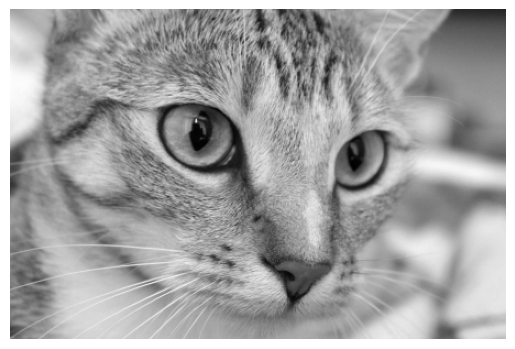

In [ ]:
# 사진 파일을 흑백으로 불러와서 보기
filename = 'sample.png'   # 내 사진을 올리려면 파일 이름으로 바꾸세요 (예: 'me.jpg')
img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
print(img is None)   # False이면 정상, True이면 파일 이름이 틀린 것
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

In [ ]:
# 사진의 크기와 왼쪽 위 5x5 칸의 숫자 보기
print(img.shape)

#위에서 5줄, 왼쪽에서 5칸
print(img[:5, :5])

(300, 451)
[[125 125 123 123 123]
 [128 127 125 124 124]
 [130 129 127 126 127]
 [134 132 130 130 128]
 [136 134 133 132 130]]


목표 결과:
```
(300, 451)
(5x5 숫자표: 0~255 사이의 숫자들)
```

### 해석해 보기
이 셀을 더블클릭해서 `____` 자리에 답을 적으세요.

1. `(300, 451)`는 사진이 높이 `300`칸, 너비 `451`칸이라는 뜻이다.
2. 사진 한 칸(픽셀)의 값이 `0`이면 `검은`색, `255`이면 `하얀`색이다.
3. 사진 한 장은 사실 `숫자`로 이루어진 표이다.

### 직접 해보기
사진을 MNIST와 같은 **28×28** 크기로 줄여 보세요. 빈칸에 알맞은 숫자를 넣으세요.

**힌트**: `cv2.resize(사진, (너비, 높이))`

(28, 28)


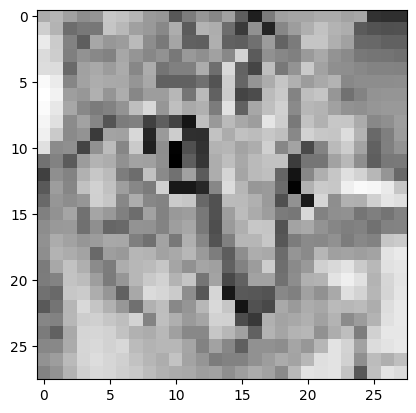

In [ ]:
# 사진을 28x28로 줄이기
small = cv2.resize(img, (28, 28))
print(small.shape)
plt.imshow(small, cmap='gray')
plt.show()

목표 결과:
```
(28, 28)
```
**28×28 사진은 숫자 `784`개짜리 표** → 아래 MNIST 손글씨 사진도 이렇게 생겼습니다.

# 1. 데이터 준비

In [ ]:
# 라이브러리 불러오기
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist  # 손글씨 숫자 사진 7만 장이 든 데이터
from tensorflow.keras.models import Sequential   # 층을 순서대로 쌓아 모델을 만드는 틀
from tensorflow.keras.layers import Input, Flatten, Dense

In [ ]:
# 손글씨 숫자 데이터 불러오기 (학습용 60000장, 테스트용 10000장)
(X_train, y_train), (X_test, y_test) = mnist.load_data()


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# 이미지 크기와 정답 앞부분 확인
print(X_train.shape)

#앞에서 10개만 보기
print(y_train[:10])

(60000, 28, 28)
[5 0 4 1 9 2 1 3 1 4]


목표 결과:
```
(60000, 28, 28)
[5 0 4 1 9 2 1 3 1 4]
```

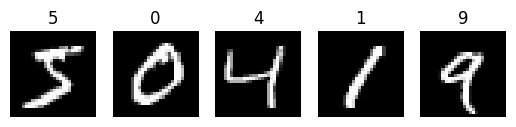

In [ ]:
# 앞의 5장을 그림과 정답으로 보기
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')
plt.show()

In [ ]:
# 이미지 한 장의 픽셀 최소값과 최댓값
print(y_train[0], X_train[0])
print(X_train[2].max(), X_train[2].min())

5 [[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 

목표 결과:
```
0 255
```
표 데이터에서 `MinMaxScaler`로 숫자 크기를 맞춘 것처럼, 픽셀값도 **0~1**로 맞춰 줍니다. 가장 큰 값 255로 나누면 됩니다.

### 1-2-1. 직접 해보기
빈칸에 알맞은 숫자를 넣어 `X_train`과 `X_test`를 0~1로 바꾸세요.

**힌트**: 픽셀의 최댓값이 얼마였나요?

In [ ]:
# 픽셀값을 0~1로 만들기
X_train = X_train / 255
X_test = X_test / 255

---
### 잠깐 멈추기
1. 나눠야 하는 수는 무엇인가요?
2. 나누면 가장 밝은 칸은 얼마가 되나요?

# 2. 신경망 모델 만들기
### 직접 해보기
`Flatten` 층과, 노드가 128개인 `Dense` 층을 빈칸에 채우세요. `model.summary()`가 목표와 같으면 성공입니다.

**힌트**: `Flatten()`은 괄호 안이 비어 있습니다.

In [ ]:
# 신경망 모델 만들기: 입력 → 층 쌓기 → 출력
model = Sequential()
model.add(Input(shape=(28, 28))) # 입력층
model.add(Flatten())                                # 28x28 이미지를 한 줄로 펼치기
model.add(Dense(128, activation='relu'))        # 노드 128개짜리 층 : 딥러닝 시
model.add(Dense(10, activation='softmax'))       # 출력층: 숫자 0~9 각각일 확률, 10개의 노드로 나눠라(최종 출력 종류가 10개)

In [ ]:
# 층마다 출력 모양과 파라미터 수 확인
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

목표 결과 (표 모양은 달라도 **숫자**를 확인하세요):
```
flatten (Flatten)        (None, 784)     0
dense (Dense)            (None, 128)     100,480
dense_1 (Dense)          (None, 10)      1,290
Total params: 101,770
```

# 3. 학습시키기

In [ ]:
# 학습 방법 정하기: 틀린 정도(loss)를 줄이도록 학습하고 정확도를 함께 기록
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

### 직접 해보기
학습용 데이터 전체를 **5번** 반복해서 학습시키세요.

**힌트**: `fit`의 `epochs=` 자리입니다.

In [ ]:
# 학습용 데이터 전체를 5번 반복해서 학습
history = model.fit(X_train, y_train, epochs=5, validation_data=(X_test, y_test))
# 32장씩 (배치 사이즈가 32) 1875번 반복하면 1 에포크 (6만장)을 학습함

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9892 - loss: 0.0355 - val_accuracy: 0.9779 - val_loss: 0.0726
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9913 - loss: 0.0282 - val_accuracy: 0.9738 - val_loss: 0.0825
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9935 - loss: 0.0217 - val_accuracy: 0.9798 - val_loss: 0.0714
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9941 - loss: 0.0193 - val_accuracy: 0.9771 - val_loss: 0.0805
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9949 - loss: 0.0154 - val_accuracy: 0.9778 - val_loss: 0.0864


- `loss` / `accuracy`: **학습용** 데이터 점수
- `val_loss` / `val_accuracy`: **테스트용**(처음 보는) 데이터 점수

숫자보다 **경향**을 보세요: loss는 내려가고 accuracy는 올라가나요?

# 4. 학습 곡선 그리고 읽기
### 직접 해보기
테스트용 loss 곡선이 그려지도록 빈칸을 채우세요.

**힌트**: 테스트용 loss의 이름은 `val_`로 시작합니다.

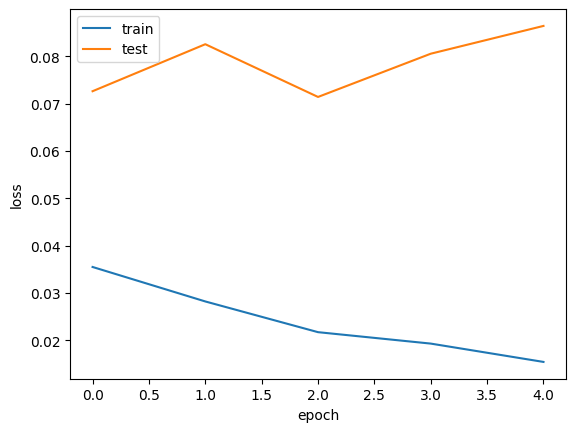

In [ ]:
# loss(틀린 정도) 곡선: 학습용과 테스트용
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

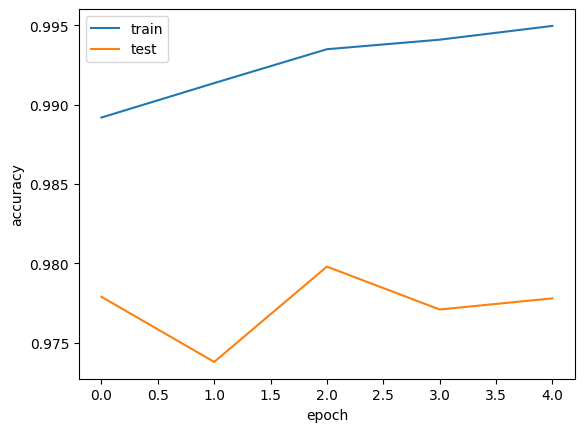

In [ ]:
# accuracy 그리기

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.show()

---
### 잠깐 멈추기
1. loss는 epoch이 지날수록 어떻게 변했나요? 그때 accuracy는 어떻게 변했나요?
2. **마지막 epoch**에서 학습용 선과 테스트용 선 중 어느 선이 더 좋은 값인가요? 왜 그럴까요?
3. epoch을 5에서 50으로 늘리면 항상 더 좋아질까요?

# 5. 직접 해보기: 노드 수를 줄이면?
노드를 128개에서 **16**개로 줄여 다시 학습하고 테스트용 정확도를 비교하세요. 빈칸은 두 곳입니다.

목표 결과 (숫자는 조금 달라도 됩니다):
```
노드 128개: 0.97xx
노드 16개: 0.94xx
```
**힌트**: 테스트용 정확도의 이름은 `'val_accuracy'`입니다.

In [ ]:
# 노드 16개짜리 작은 모델 만들고 학습시키기
small_model = Sequential()
small_model.add(Input(shape=(28, 28)))
small_model.add(Flatten())
small_model.add(Dense(16, activation='relu'))
small_model.add(Dense(10, activation='softmax'))
small_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
small_history = small_model.fit(X_train, y_train, epochs=5, validation_data=(X_test, y_test))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8750 - loss: 0.4380 - val_accuracy: 0.9264 - val_loss: 0.2511
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9317 - loss: 0.2378 - val_accuracy: 0.9369 - val_loss: 0.2169
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9422 - loss: 0.2045 - val_accuracy: 0.9429 - val_loss: 0.1896
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9456 - loss: 0.1864 - val_accuracy: 0.9444 - val_loss: 0.1891
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9490 - loss: 0.1759 - val_accuracy: 0.9461 - val_loss: 0.1884


In [ ]:
# 마지막 epoch의 테스트용 정확도 비교
print('노드 128개:', round(history.history['val_accuracy'][-1], 4))
print('노드 16개:', round(small_history.history['val_accuracy'][-1], 4))

노드 128개: 0.9778
노드 16개: 0.9461


---
## 오늘 정리
- 신경망은 **층을 쌓아** 만든 모델이다.
- 픽셀값(0~255)은 255로 나눠 **0~1**로 만든다.
- 학습은 **epoch** 단위로 반복하고, loss는 내려가고 accuracy는 올라간다.
- **학습 곡선**은 학습용과 테스트용 선을 함께 본다.